# Mietpreis-Modell für NRW mit scikit-learn

**Ziel:** Aus öffentlichen Mietinseraten soll ein Modell lernen, die **Kaltmiete** einer Wohnung vorherzusagen.

**Datenquelle:** [Apartment rental offers in Germany](https://www.kaggle.com/datasets/corrieaar/apartment-rental-offers-in-germany) (Kaggle), Inserate von ImmobilienScout24.
Ich verwende nur Wohnungen aus **Nordrhein-Westfalen**.

**Ablauf:**
1. Daten laden
2. Daten erkunden
3. Daten bereinigen
4. Features vorbereiten
5. Train/Test-Split
6. Modelle trainieren (Lineare Regression und Random Forest)
7. Auswerten
8. Fazit

## 0. Bibliotheken importieren

- **pandas**: Tabellen laden und bearbeiten
- **numpy**: Rechnen mit Zahlen
- **matplotlib**: Diagramme
- **scikit-learn**: Machine Learning

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42  # sorgt dafür, dass Ergebnisse bei jedem Lauf gleich sind

## 1. Daten laden

Die Datei `immo_data.csv` muss im selben Ordner wie dieses Notebook liegen.
Download: Kaggle Seite öffnen, auf **Download** klicken, ZIP entpacken.

In [19]:
df_raw = pd.read_csv("immo_data.csv")

print("Zeilen und Spalten:", df_raw.shape)
df_raw.head()

Zeilen und Spalten: (268850, 49)


,regio1,serviceCharge,heatingType,telekomTvOffer,telekomHybridUploadSpeed,newlyConst,balcony,picturecount,pricetrend,telekomUploadSpeed,totalRent,yearConstructed,scoutId,noParkSpaces,firingTypes,hasKitchen,geo_bln,cellar,yearConstructedRange,baseRent,houseNumber,livingSpace,geo_krs,condition,interiorQual,petsAllowed,street,streetPlain,lift,baseRentRange,typeOfFlat,geo_plz,noRooms,thermalChar,floor,numberOfFloors,noRoomsRange,garden,livingSpaceRange,regio2,regio3,description,facilities,heatingCosts,energyEfficiencyClass,lastRefurbish,electricityBasePrice,electricityKwhPrice,date
0,Nordrhein_Westfalen,245.00,central_heating,ONE_YEAR_FREE,NaN,False,False,6,4.62,10.0,840.0,1965.0,96107057,1.0,oil,False,Nordrhein_Westfalen,True,2.0,595.0,244,86.00,Dortmund,well_kept,normal,NaN,Sch&uuml;ruferstra&szlig;e,Schüruferstraße,False,4,ground_floor,44269,4.0,181.4,1.0,3.0,4,True,4,Dortmund,Schüren,Die ebenerdig zu erreichende Erdgeschosswohnun...,Die Wohnung ist mit Laminat ausgelegt. Das Bad...,NaN,NaN,NaN,NaN,NaN,May19
1,Rheinland_Pfalz,134.00,self_contained_central_heating,ONE_YEAR_FREE,NaN,False,True,8,3.47,10.0,NaN,1871.0,111378734,2.0,gas,False,Rheinland_Pfalz,False,1.0,800.0,NaN,89.00,Rhein_Pfalz_Kreis,refurbished,normal,no,no_information,NaN,False,5,ground_floor,67459,3.0,NaN,NaN,NaN,3,False,4,Rhein_Pfalz_Kreis,Böhl_Iggelheim,Alles neu macht der Mai – so kann es auch für ...,NaN,NaN,NaN,2019.0,NaN,NaN,May19
2,Sachsen,255.00,floor_heating,ONE_YEAR_FREE,10.0,True,True,8,2.72,2.4,1300.0,2019.0,113147523,1.0,NaN,False,Sachsen,True,9.0,965.0,4,83.80,Dresden,first_time_use,sophisticated,NaN,Turnerweg,Turnerweg,True,6,apartment,1097,3.0,NaN,3.0,4.0,3,False,4,Dresden,Äußere_Neustadt_Antonstadt,Der Neubau entsteht im Herzen der Dresdner Neu...,"* 9 m² Balkon\n* Bad mit bodengleicher Dusche,...",NaN,NaN,NaN,NaN,NaN,Oct19
3,Sachsen,58.15,district_heating,ONE_YEAR_FREE,NaN,False,True,9,1.53,40.0,NaN,1964.0,108890903,NaN,district_heating,False,Sachsen,False,2.0,343.0,35,58.15,Mittelsachsen_Kreis,NaN,NaN,NaN,Gl&uuml;ck-Auf-Stra&szlig;e,Glück-Auf-Straße,False,2,other,9599,3.0,86.0,3.0,NaN,3,False,2,Mittelsachsen_Kreis,Freiberg,Abseits von Lärm und Abgasen in Ihre neue Wohn...,NaN,87.23,NaN,NaN,NaN,NaN,May19
4,Bremen,138.00,self_contained_central_heating,NaN,NaN,False,True,19,2.46,NaN,903.0,1950.0,114751222,NaN,gas,False,Bremen,False,1.0,765.0,10,84.97,Bremen,refurbished,NaN,NaN,Hermann-Henrich-Meier-Allee,Hermann-Henrich-Meier-Allee,False,5,apartment,28213,3.0,188.9,1.0,NaN,3,False,4,Bremen,Neu_Schwachhausen,Es handelt sich hier um ein saniertes Mehrfami...,Diese Wohnung wurde neu saniert und ist wie fo...,NaN,NaN,NaN,NaN,NaN,Feb20


In [20]:
# Welche Spalten gibt es und welchen Datentyp haben sie?
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 268850 entries, 0 to 268849
Data columns (total 49 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   regio1                    268850 non-null  str    
 1   serviceCharge             261941 non-null  float64
 2   heatingType               223994 non-null  str    
 3   telekomTvOffer            236231 non-null  str    
 4   telekomHybridUploadSpeed  45020 non-null   float64
 5   newlyConst                268850 non-null  bool   
 6   balcony                   268850 non-null  bool   
 7   picturecount              268850 non-null  int64  
 8   pricetrend                267018 non-null  float64
 9   telekomUploadSpeed        235492 non-null  float64
 10  totalRent                 228333 non-null  float64
 11  yearConstructed           211805 non-null  float64
 12  scoutId                   268850 non-null  int64  
 13  noParkSpaces              93052 non-null   float64
 14 

Der Datensatz enthält ganz Deutschland. Für dieses Projekt filtere ich auf **NRW**.
Die Spalte `regio1` enthält das Bundesland, `regio2` die Stadt bzw. den Kreis.

In [21]:
df = df_raw[df_raw["regio1"] == "Nordrhein_Westfalen"].copy()
print("Inserate in NRW:", len(df))

Inserate in NRW: 62863


## 2. Daten erkunden

Ich wähle die Spalten aus, die für die Miete wichtig sein könnten.

| Spalte | Bedeutung |
|---|---|
| `baseRent` | Kaltmiete in € (**Zielvariable**) |
| `livingSpace` | Wohnfläche in m² |
| `noRooms` | Anzahl Zimmer |
| `yearConstructed` | Baujahr |
| `floor` | Etage |
| `balcony`, `hasKitchen`, `cellar`, `lift`, `garden`, `newlyConst` | Ja/Nein Merkmale |
| `condition` | Zustand (z. B. renoviert, gepflegt) |
| `interiorQual` | Qualität der Ausstattung |
| `typeOfFlat` | Wohnungstyp (Etagenwohnung, Dachgeschoss ...) |
| `heatingType` | Heizungsart |
| `regio2` | Stadt bzw. Kreis |

Bewusst **nicht** verwendet: `totalRent` und `serviceCharge`. Die Warmmiete enthält die Kaltmiete schon,
das Modell würde also "schummeln".

In [22]:
ZIEL = "baseRent"
NUM_SPALTEN = ["livingSpace", "noRooms", "yearConstructed", "floor"]
BOOL_SPALTEN = ["balcony", "hasKitchen", "cellar", "lift", "garden", "newlyConst"]
KAT_SPALTEN = ["condition", "interiorQual", "typeOfFlat", "heatingType", "regio2"]

df = df[[ZIEL] + NUM_SPALTEN + BOOL_SPALTEN + KAT_SPALTEN]
df.describe()

,baseRent,livingSpace,noRooms,yearConstructed,floor
count,62863.000000,62863.000000,62863.000000,50811.000000,51618.000000
mean,601.637195,74.746277,2.682243,1969.039873,1.902573
std,610.535788,71.930019,1.521997,37.804983,2.242125
min,0.000000,0.000000,1.000000,1036.000000,-1.000000
25%,371.000000,56.650000,2.000000,1955.000000,1.000000
50%,490.000000,70.000000,3.000000,1968.000000,2.000000
75%,700.000000,86.000000,3.000000,1993.000000,3.000000
max,120000.000000,14000.000000,230.000000,2021.000000,390.000000


### Fehlende Werte
Wie viel Prozent fehlen pro Spalte?

In [23]:
(df.isna().mean() * 100).sort_values(ascending=False).round(1)

interiorQual       41.1
condition          27.1
yearConstructed    19.2
floor              17.9
heatingType        14.4
typeOfFlat          7.5
livingSpace         0.0
baseRent            0.0
cellar              0.0
hasKitchen          0.0
balcony             0.0
noRooms             0.0
newlyConst          0.0
garden              0.0
lift                0.0
regio2              0.0
dtype: float64

### Verteilung der Kaltmiete und der Wohnfläche

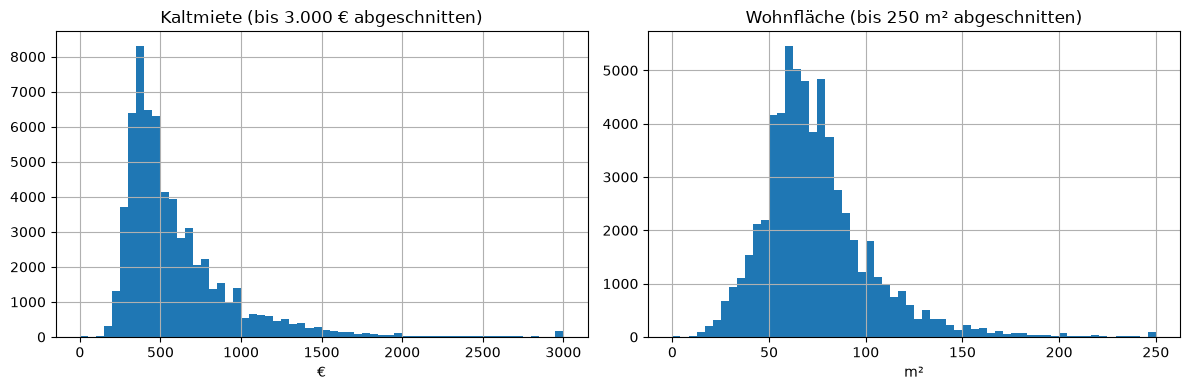

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df[ZIEL].clip(upper=3000).hist(bins=60, ax=axes[0])
axes[0].set_title("Kaltmiete (bis 3.000 € abgeschnitten)")
axes[0].set_xlabel("€")
df["livingSpace"].clip(upper=250).hist(bins=60, ax=axes[1])
axes[1].set_title("Wohnfläche (bis 250 m² abgeschnitten)")
axes[1].set_xlabel("m²")
plt.tight_layout()
plt.show()

### Zusammenhang zwischen Fläche und Miete
Erwartung: Je größer die Wohnung, desto höher die Miete.

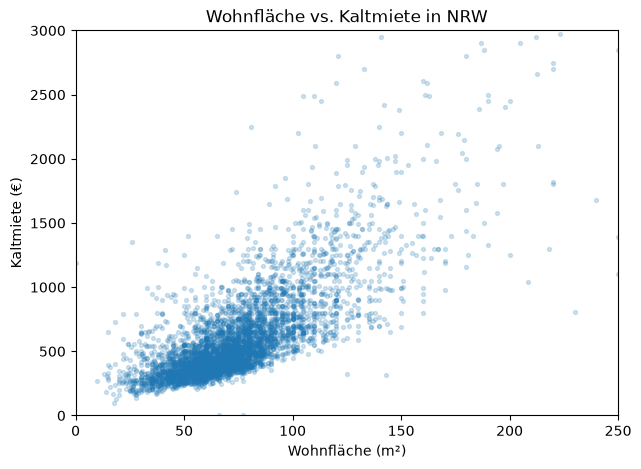

In [25]:
stichprobe = df.sample(min(5000, len(df)), random_state=RANDOM_STATE)
plt.figure(figsize=(7, 5))
plt.scatter(stichprobe["livingSpace"], stichprobe[ZIEL], alpha=0.2, s=8)
plt.xlim(0, 250)
plt.ylim(0, 3000)
plt.xlabel("Wohnfläche (m²)")
plt.ylabel("Kaltmiete (€)")
plt.title("Wohnfläche vs. Kaltmiete in NRW")
plt.show()

## 3. Daten bereinigen

1. Zeilen ohne Miete oder Fläche entfernen (ohne Zielwert kann das Modell nichts lernen)
2. Unrealistische Werte und Tippfehler rausfiltern
3. Ja/Nein Spalten in 0 und 1 umwandeln
4. Seltene Städte zu "Sonstige" zusammenfassen

In [26]:
vorher = len(df)

# 1. Pflichtwerte
df = df.dropna(subset=[ZIEL, "livingSpace"])

# 2. Plausibilitätsgrenzen
df = df[df[ZIEL].between(100, 5000)]
df = df[df["livingSpace"].between(10, 300)]
df["qm_preis"] = df[ZIEL] / df["livingSpace"]
df = df[df["qm_preis"].between(3, 40)]        # unter 3 €/m² oder über 40 €/m² ist unrealistisch
df = df.drop(columns="qm_preis")

df = df[df["noRooms"].between(1, 8) | df["noRooms"].isna()]
df = df[df["yearConstructed"].between(1800, 2025) | df["yearConstructed"].isna()]
df = df[df["floor"].between(-1, 30) | df["floor"].isna()]

print(f"Entfernt: {vorher - len(df)} Zeilen, übrig: {len(df)}")

Entfernt: 260 Zeilen, übrig: 62603


In [27]:
# 3. Ja/Nein Spalten: True/False wird zu 1/0
for spalte in BOOL_SPALTEN:
    df[spalte] = df[spalte].astype(float)

# 4. Nur die 25 häufigsten Städte/Kreise behalten, Rest wird "Sonstige"
top_staedte = df["regio2"].value_counts().nlargest(25).index
df["regio2"] = df["regio2"].where(df["regio2"].isin(top_staedte), "Sonstige")

df["regio2"].value_counts().head(10)

regio2
Sonstige                14558
Essen                    4341
Düsseldorf               3681
Duisburg                 3505
Dortmund                 3129
Gelsenkirchen            2937
Recklinghausen_Kreis     2752
Köln                     2673
Wuppertal                2371
Bochum                   2003
Name: count, dtype: int64

## 4. Features vorbereiten

Ein Modell kann nur mit Zahlen rechnen. Darum:

- **Zahlen-Spalten:** fehlende Werte mit dem **Median** auffüllen
- **Kategorie-Spalten** (z. B. Stadt): fehlende Werte als "unbekannt" markieren und dann per **One-Hot-Encoding**
  in einzelne 0/1 Spalten umwandeln. Aus `regio2 = Köln` wird z. B. die Spalte `regio2_Köln = 1`.

Ich packe das in eine **Pipeline**. Vorteil: Die Vorbereitung wird nur auf den Trainingsdaten gelernt
und dann identisch auf die Testdaten angewendet. So gibt es keine Informationen aus dem Test, die ins Training rutschen.

In [28]:
vorverarbeitung = ColumnTransformer([
    ("zahlen", SimpleImputer(strategy="median"), NUM_SPALTEN + BOOL_SPALTEN),
    ("kategorien", Pipeline([
        ("auffuellen", SimpleImputer(strategy="constant", fill_value="unbekannt")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), KAT_SPALTEN),
])

## 5. Train/Test-Split

- **X** = Merkmale der Wohnung
- **y** = Kaltmiete

80 % der Daten zum Lernen, 20 % zum Testen. Die Testdaten sieht das Modell beim Training nie.

In [29]:
X = df.drop(columns=ZIEL)
y = df[ZIEL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Training:", X_train.shape, "Test:", X_test.shape)

Training: (50082, 15) Test: (12521, 15)


## 6. Modelle trainieren

**Baseline: Lineare Regression.** Einfaches Modell, das eine gerade Linie bzw. Ebene durch die Daten legt.

**Vergleich: Random Forest.** Viele Entscheidungsbäume, deren Ergebnisse gemittelt werden.
Kann auch nicht lineare Zusammenhänge lernen (z. B. Altbau in Köln teurer als Altbau auf dem Land).

In [30]:
modelle = {
    "Lineare Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE
    ),
}

pipelines = {}
for name, modell in modelle.items():
    pipe = Pipeline([("vorverarbeitung", vorverarbeitung), ("modell", modell)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    print(f"{name} trainiert")

Lineare Regression trainiert
Random Forest trainiert


## 7. Auswerten

- **MAE** (Mean Absolute Error): Um wie viel Euro liegt die Vorhersage im Schnitt daneben? Kleiner ist besser.
- **R²**: Wie viel der Preisunterschiede erklärt das Modell? 1,0 wäre perfekt, 0 heißt "nicht besser als der Durchschnitt".

Zum Vergleich auch ein ganz naiver Ansatz: immer den Durchschnittspreis vorhersagen.

In [31]:
ergebnisse = []

naiv = np.full(len(y_test), y_train.mean())
ergebnisse.append({"Modell": "Naiv (Durchschnitt)",
                   "MAE (€)": mean_absolute_error(y_test, naiv),
                   "R²": r2_score(y_test, naiv)})

for name, pipe in pipelines.items():
    vorhersage = pipe.predict(X_test)
    ergebnisse.append({"Modell": name,
                       "MAE (€)": mean_absolute_error(y_test, vorhersage),
                       "R²": r2_score(y_test, vorhersage)})

pd.DataFrame(ergebnisse).round(2)

,Modell,MAE (€),R²
0,Naiv (Durchschnitt),247.20,-0.00
1,Lineare Regression,100.06,0.81
2,Random Forest,82.15,0.86


### Vorhersage gegen echten Preis (Random Forest)
Liegen die Punkte nahe an der roten Linie, ist die Vorhersage gut.

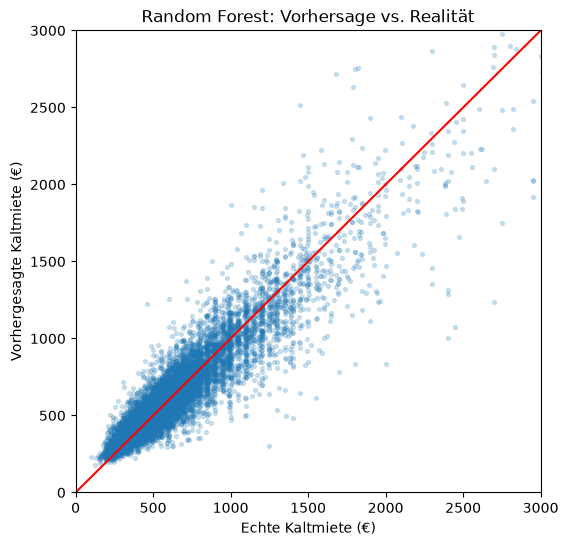

In [32]:
vorhersage_rf = pipelines["Random Forest"].predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, vorhersage_rf, alpha=0.2, s=8)
plt.plot([0, 3000], [0, 3000], color="red")
plt.xlim(0, 3000)
plt.ylim(0, 3000)
plt.xlabel("Echte Kaltmiete (€)")
plt.ylabel("Vorhergesagte Kaltmiete (€)")
plt.title("Random Forest: Vorhersage vs. Realität")
plt.show()

### Welche Merkmale beeinflussen den Preis am stärksten?
Der Random Forest misst, wie stark jedes Merkmal zur Vorhersage beiträgt (Feature Importance).

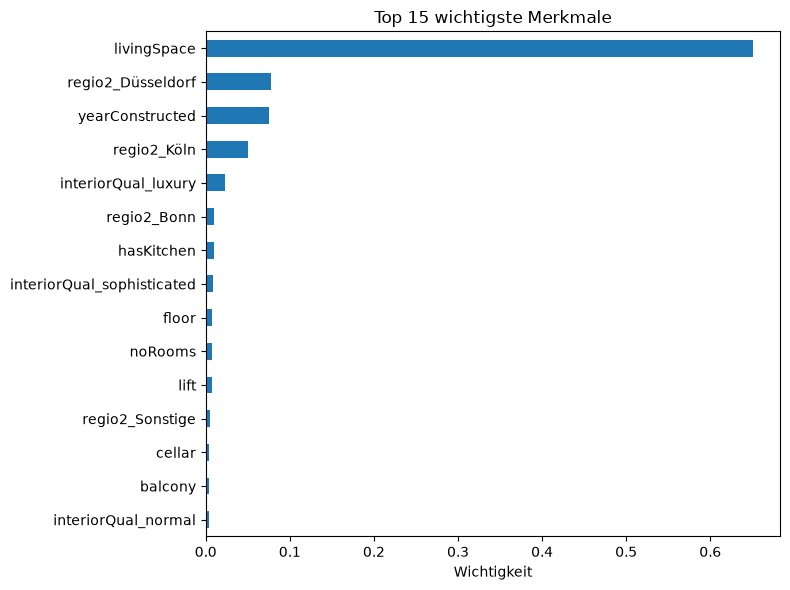

In [33]:
rf_pipe = pipelines["Random Forest"]
namen = rf_pipe.named_steps["vorverarbeitung"].get_feature_names_out()
wichtigkeit = pd.Series(rf_pipe.named_steps["modell"].feature_importances_, index=namen)

# Namen lesbarer machen, z. B. "kategorien__regio2_Köln" wird "regio2_Köln"
wichtigkeit.index = wichtigkeit.index.str.replace(r"^(zahlen|kategorien)__", "", regex=True)
top15 = wichtigkeit.sort_values().tail(15)

plt.figure(figsize=(8, 6))
top15.plot(kind="barh")
plt.title("Top 15 wichtigste Merkmale")
plt.xlabel("Wichtigkeit")
plt.tight_layout()
plt.show()

### Praxistest: Was kostet eine Beispielwohnung?
70 m², 3 Zimmer, Baujahr 1995, 2. Etage, Balkon, Keller, gepflegt, in Köln.

In [34]:
beispiel = pd.DataFrame([{
    "livingSpace": 70, "noRooms": 3, "yearConstructed": 1995, "floor": 2,
    "balcony": 1, "hasKitchen": 0, "cellar": 1, "lift": 0, "garden": 0, "newlyConst": 0,
    "condition": "well_kept", "interiorQual": "normal",
    "typeOfFlat": "apartment", "heatingType": "central_heating", "regio2": "Köln",
}])

for name, pipe in pipelines.items():
    print(f"{name}: {pipe.predict(beispiel)[0]:.0f} € Kaltmiete")

Lineare Regression: 791 € Kaltmiete
Random Forest: 697 € Kaltmiete


## 8. Fazit


Modell	MAE (€)	R²
0	Naiv (Durchschnitt)	247.20	-0.00
1	Lineare Regression	100.06	0.81
2	Random Forest	82.15	0.86

**Was funktioniert hat**
- Beide Modelle sind deutlich besser als der naive Durchschnitt. Der Random Forest erreicht einen MAE von **247.20 €** und ein R² von **-0.00**, die lineare Regression **100.06 €** bzw. **0.81**.
- Die wichtigsten Merkmale laut Random Forest sind **0.86** (siehe Diagramm in Abschnitt 7).
- Die Pipeline sorgt dafür, dass Vorbereitung und Modell sauber zusammen gespeichert und angewendet werden.

**Grenzen**
- Es sind **Angebotsmieten** aus Inseraten, keine tatsächlich gezahlten Mieten.
- Die Daten stammen aus den Jahren 2018 bis 2020 und bilden den heutigen Markt nicht mehr genau ab.
- Die Lage ist nur grob auf Stadtebene erfasst. Innerhalb von Köln gibt es große Unterschiede zwischen den Vierteln.

**Mögliche Verbesserungen**
- Stadtteil (`regio3`) oder Postleitzahl als genaueres Lagemerkmal
- Den **Preis pro m²** vorhersagen statt der Gesamtmiete
- Hyperparameter optimieren (z. B. mit `GridSearchCV`)
- Weitere Modelle testen, z. B. Gradient Boosting